# Лабораторна робота: Аналіз даних у pandas та EDA
**Дисципліна:** Машинне навчання

**Мета:** відпрацювати завантаження та первинне обстеження даних, індексацію, фільтрацію, очищення, групування, об’єднання, переформатування, пошук викидів і базову візуалізацію засобами `pandas`.

## 0. Підготовка середовища

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("pandas:", pd.__version__)
print("numpy:", np.__version__)

pandas: 2.2.3
numpy: 2.3.5


## 1. Створення навчального набору даних

In [2]:
rng = np.random.default_rng(42)
n = 120

cities = np.array(["Kyiv", "Lviv", "Odesa", "Dnipro", "Kharkiv"])
segments = np.array(["basic", "standard", "premium"])

customers = pd.DataFrame({
    "customer_id": np.arange(1001, 1001 + n),
    "age": rng.integers(18, 70, size=n).astype(float),
    "city": rng.choice(cities, size=n, p=[0.30, 0.20, 0.18, 0.16, 0.16]),
    "segment": rng.choice(segments, size=n, p=[0.45, 0.40, 0.15]),
    "signup_date": pd.Timestamp("2022-01-01") + pd.to_timedelta(
        rng.integers(0, 1600, size=n), unit="D"
    ),
    "orders": rng.poisson(7, size=n),
    "spend": np.round(rng.gamma(shape=2.3, scale=280, size=n), 2),
    "churn": rng.choice([0, 1], size=n, p=[0.78, 0.22]),
})

# Навмисно додаємо проблеми якості даних
customers.loc[[5, 18, 44], "age"] = np.nan
customers.loc[[9, 27, 78, 101], "spend"] = np.nan
customers.loc[12, "city"] = " kyiv "
customers.loc[31, "city"] = "LVIV"
customers.loc[66, "segment"] = None
customers.loc[88, "spend"] = -150.0

# Два повні дублікати
customers = pd.concat([customers, customers.iloc[[3, 15]]], ignore_index=True)

customers.to_csv("customers_eda.csv", index=False)
print("Файл створено: customers_eda.csv")
print("Розмір:", customers.shape)
customers.head()

Файл створено: customers_eda.csv
Розмір: (122, 8)


,customer_id,age,city,segment,signup_date,orders,spend,churn
0,1001,22.0,Odesa,premium,2024-09-13,4,347.14,0
1,1002,58.0,Lviv,premium,2025-05-31,9,706.18,0
2,1003,52.0,Odesa,standard,2025-03-28,11,1164.91,0
3,1004,40.0,Dnipro,basic,2022-08-04,7,77.99,0
4,1005,40.0,Odesa,standard,2025-08-14,8,574.75,0


## 2. Завантаження даних

In [3]:
df = pd.read_csv("customers_eda.csv", parse_dates=["signup_date"])
print("shape:", df.shape)
print("columns:", df.columns.tolist())
df.head()

shape: (122, 8)
columns: ['customer_id', 'age', 'city', 'segment', 'signup_date', 'orders', 'spend', 'churn']


,customer_id,age,city,segment,signup_date,orders,spend,churn
0,1001,22.0,Odesa,premium,2024-09-13,4,347.14,0
1,1002,58.0,Lviv,premium,2025-05-31,9,706.18,0
2,1003,52.0,Odesa,standard,2025-03-28,11,1164.91,0
3,1004,40.0,Dnipro,basic,2022-08-04,7,77.99,0
4,1005,40.0,Odesa,standard,2025-08-14,8,574.75,0


# Завдання 1. Первинний аудит даних

Потрібно визначити розмір набору, типи стовпців, кількість унікальних значень, частку пропусків та назвати потенційні проблеми якості.

In [4]:
rows, cols = df.shape
print(f"Розмір датафрейму: {rows} рядків та {cols} стовпців")

print("\n--- Типи стовпців ---")
print(df.dtypes)

print("\n--- Кількість унікальних значень ---")
print(df.nunique())

print("\n--- Частка пропусків, % ---")
missing_share = df.isna().mean() * 100
print(missing_share.round(2))

print("\nПовних дублікатів:", df.duplicated().sum())
print("Дублікатів customer_id:", df.duplicated(subset=["customer_id"]).sum())
print("Від'ємних spend:", (df["spend"] < 0).sum())
print("Унікальні city:", df["city"].unique())

Розмір датафрейму: 122 рядків та 8 стовпців

--- Типи стовпців ---
customer_id             int64
age                   float64
city                   object
segment                object
signup_date    datetime64[ns]
orders                  int64
spend                 float64
churn                   int64
dtype: object

--- Кількість унікальних значень ---
customer_id    120
age             45
city             7
segment          3
signup_date    117
orders          14
spend          116
churn            2
dtype: int64

--- Частка пропусків, % ---
customer_id    0.00
age            2.46
city           0.00
segment        0.82
signup_date    0.00
orders         0.00
spend          3.28
churn          0.00
dtype: float64

Повних дублікатів: 2
Дублікатів customer_id: 2
Від'ємних spend: 1
Унікальні city: ['Odesa' 'Lviv' 'Dnipro' 'Kyiv' ' kyiv ' 'LVIV' 'Kharkiv']


**Висновок до завдання 1.** Набір містить 122 рядки та 8 стовпців. Виявлено пропуски в `age`, `segment` і `spend`, два повні дублікати, неконсистентне написання назв міст (`" kyiv "`, `"LVIV"`) та від’ємне значення `spend`. Ці проблеми необхідно врахувати перед подальшим аналізом.

# Завдання 2. Фільтрація

Створити `task2` для клієнтів віком 30–50 років, із сегменту `premium` або `standard`, витратами понад 600 та залишити лише задані стовпці. Результат відсортувати за `spend` за спаданням.

In [5]:
condition_age = df["age"].between(30, 50)
condition_segment = df["segment"].isin(["premium", "standard"])
condition_spend = df["spend"] > 600

mask = condition_age & condition_segment & condition_spend
selected_columns = ["customer_id", "age", "city", "segment", "spend"]

task2 = (
    df.loc[mask, selected_columns]
      .sort_values("spend", ascending=False)
)

print(task2)

     customer_id   age     city   segment    spend
29          1030  41.0    Odesa  standard  1651.09
84          1085  50.0     Lviv   premium  1386.54
118         1119  30.0  Kharkiv  standard  1243.22
21          1022  37.0     Lviv   premium  1162.84
75          1076  42.0     Kyiv  standard   997.35
43          1044  36.0  Kharkiv   premium   963.23
76          1077  35.0  Kharkiv  standard   898.33
64          1065  39.0     Kyiv  standard   870.96
30          1031  41.0     Kyiv  standard   851.50
65          1066  34.0     Lviv   premium   848.28
115         1116  47.0     Kyiv   premium   795.16
112         1113  46.0     Kyiv   premium   770.63
20          1021  44.0    Odesa  standard   711.92
81          1082  40.0     Lviv  standard   704.74
38          1039  32.0     Kyiv   premium   701.06
114         1115  44.0     Kyiv  standard   604.29


**Висновок до завдання 2.** За допомогою булевої маски та `loc` відібрано лише клієнтів, які одночасно відповідають усім трьом умовам. Сортування дозволяє одразу побачити клієнтів із найбільшими витратами.

# Завдання 3. Очищення

In [6]:
df_clean = df.copy()

# Видаляємо повні дублікати
df_clean = df_clean.drop_duplicates().copy()

# Нормалізуємо назви міст
df_clean["city"] = df_clean["city"].str.strip().str.title()

# Від'ємні витрати вважаємо помилковим значенням
df_clean.loc[df_clean["spend"] < 0, "spend"] = np.nan

print("Розмір після видалення дублікатів:", df_clean.shape)
print("\nКількість пропусків після очищення:")
print(df_clean.isna().sum())
print("\nМіста після нормалізації:")
print(df_clean["city"].value_counts())

Розмір після видалення дублікатів: (120, 8)

Кількість пропусків після очищення:
customer_id    0
age            3
city           0
segment        1
signup_date    0
orders         0
spend          5
churn          0
dtype: int64

Міста після нормалізації:
city
Kyiv       38
Lviv       28
Odesa      24
Dnipro     16
Kharkiv    14
Name: count, dtype: int64


**Висновок до завдання 3.** Повні дублікати видалено, текст у `city` уніфіковано, а некоректне від’ємне значення `spend` перетворено на пропуск. Пропуски в `age` і `spend` доцільно імпутувати після поділу на train/test, використовуючи статистики лише train. Пропуск `segment` можна або позначити окремою категорією `unknown`, або видалити рядок, якщо обґрунтовано, що він не придатний для аналізу.

# Завдання 4. Групова аналітика

In [7]:
task4 = (
    df_clean.groupby("segment", as_index=False, dropna=False)
    .agg(
        customer_count=("customer_id", "nunique"),
        mean_orders=("orders", "mean"),
        median_spend=("spend", "median"),
        total_spend=("spend", "sum"),
        churn_rate=("churn", "mean")
    )
    .sort_values("churn_rate", ascending=False)
)

task4.round(3)

,segment,customer_count,mean_orders,median_spend,total_spend,churn_rate
3,NaN,1,6.000,777.760,777.76,1.000
2,standard,43,7.000,503.860,27178.88,0.326
0,basic,58,6.793,668.135,37335.78,0.241
1,premium,18,7.389,738.405,12931.55,0.222


**Висновок до завдання 4.** Групування дає змогу порівняти сегменти за активністю, витратами та відтоком. Сортування за `churn_rate` показує сегменти в порядку спадання частки клієнтів, які припинили користування послугами.

# Завдання 5. Ознаки на основі дат

In [8]:
date_features = df_clean.copy()
date_features["signup_date"] = pd.to_datetime(date_features["signup_date"])
date_features["signup_year"] = date_features["signup_date"].dt.year
date_features["signup_quarter"] = date_features["signup_date"].dt.quarter

target_date = pd.Timestamp("2026-09-07")
date_features["tenure_days"] = (target_date - date_features["signup_date"]).dt.days

year_counts = date_features["signup_year"].value_counts()
top_year = year_counts.idxmax()
top_year_count = year_counts.max()

print(date_features[["customer_id", "signup_date", "signup_year",
                     "signup_quarter", "tenure_days"]].head())
print("\nКількість реєстрацій за роками:")
print(year_counts.sort_index())
print(f"\nРік з найбільшою кількістю реєстрацій: {top_year} ({top_year_count} клієнтів)")

   customer_id signup_date  signup_year  signup_quarter  tenure_days
0         1001  2024-09-13         2024               3          724
1         1002  2025-05-31         2025               2          464
2         1003  2025-03-28         2025               1          528
3         1004  2022-08-04         2022               3         1495
4         1005  2025-08-14         2025               3          389

Кількість реєстрацій за роками:
signup_year
2022    22
2023    21
2024    37
2025    27
2026    13
Name: count, dtype: int64

Рік з найбільшою кількістю реєстрацій: 2024 (37 клієнтів)


**Висновок до завдання 5.** Із дати реєстрації сформовано три корисні ознаки: рік, квартал і тривалість співпраці. `tenure_days` потенційно може бути корисною ознакою для прогнозування churn.

# Завдання 6. Об’єднання таблиць

In [9]:
segment_info = pd.DataFrame({
    "segment": ["premium", "standard", "basic"],
    "discount_rate": [0.15, 0.05, 0.00],
    "support_level": ["priority", "standard", "basic"]
})

df_merged = df_clean.merge(
    segment_info,
    on="segment",
    how="left",
    validate="many_to_one",
    indicator=True
)

print(df_merged.head())
print("\nРезультат merge:")
print(df_merged["_merge"].value_counts())

   customer_id   age    city  ... discount_rate support_level  _merge
0         1001  22.0   Odesa  ...          0.15      priority    both
1         1002  58.0    Lviv  ...          0.15      priority    both
2         1003  52.0   Odesa  ...          0.05      standard    both
3         1004  40.0  Dnipro  ...          0.00         basic    both
4         1005  40.0   Odesa  ...          0.05      standard    both

[5 rows x 11 columns]

Результат merge:
_merge
both          119
left_only       1
right_only      0
Name: count, dtype: int64


**Висновок до завдання 6.** Очікується зв’язок **many-to-one**: багато клієнтів можуть належати одному сегменту, але кожний сегмент у `segment_info` має лише один набір характеристик. Параметр `validate="many_to_one"` перевіряє цю умову під час об’єднання.

# Завдання 7. Pivot table

In [10]:
pivot_spend = df_clean.pivot_table(
    index="city",
    columns="segment",
    values="spend",
    aggfunc="median"
)

stacked = pivot_spend.stack()
max_comb = stacked.idxmax()
max_val = stacked.max()

print("Pivot Table — медіана spend:")
print(pivot_spend.round(2))
print(f"\nНайбільша медіана витрат: {max_val:.2f}")
print(f"Комбінація місто–сегмент: {max_comb[0]} — {max_comb[1]}")

Pivot Table — медіана spend:
segment   basic  premium  standard
city                              
Dnipro   703.23  1254.48    456.84
Kharkiv  533.90   762.48    767.88
Kyiv     663.68   701.06    727.90
Lviv     679.78   777.23    425.10
Odesa    672.59   639.00    489.18

Найбільша медіана витрат: 1254.48
Комбінація місто–сегмент: Dnipro — premium


**Висновок до завдання 7.** `pivot_table` дозволяє компактно порівняти типові витрати клієнтів між містами та сегментами. Медіана є стійкішою до великих значень, ніж середнє.

# Завдання 8. Візуалізація

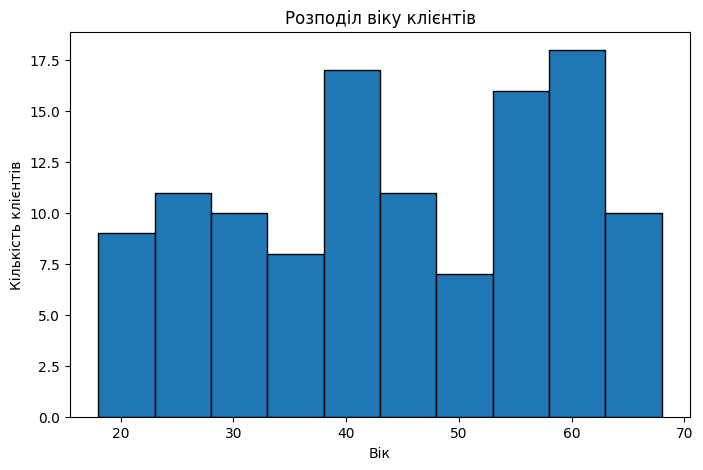

In [11]:
# 1. Розподіл age
plt.figure(figsize=(8, 5))
df_clean["age"].dropna().plot(kind="hist", bins=10, edgecolor="black")
plt.title("Розподіл віку клієнтів")
plt.xlabel("Вік")
plt.ylabel("Кількість клієнтів")
plt.show()

**Інтерпретація.** Гістограма показує, як клієнти розподілені за віком. Вибірка охоплює широкий віковий діапазон, тому `age` може містити корисну інформацію для подальшого аналізу.

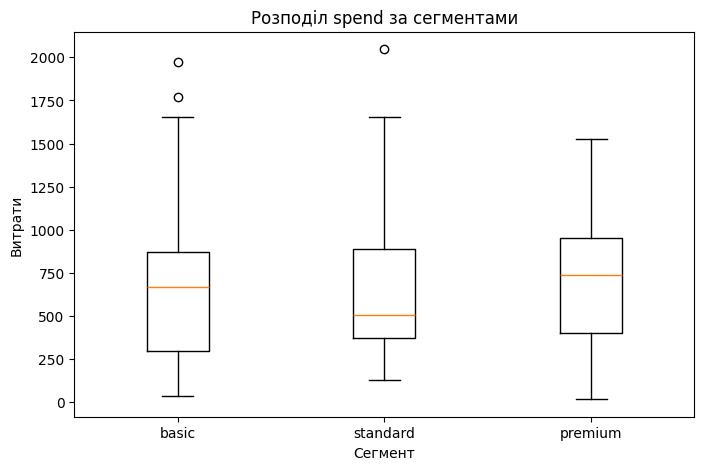

In [12]:
# 2. Boxplot spend за сегментами
segments_for_plot = ["basic", "standard", "premium"]
box_data = [
    df_clean.loc[df_clean["segment"] == segment, "spend"].dropna()
    for segment in segments_for_plot
]

plt.figure(figsize=(8, 5))
plt.boxplot(box_data, tick_labels=segments_for_plot)
plt.title("Розподіл spend за сегментами")
plt.xlabel("Сегмент")
plt.ylabel("Витрати")
plt.show()

**Інтерпретація.** Boxplot дає змогу порівняти медіани, розкид та потенційні екстремальні значення `spend` між сегментами. Видно, що розподіли витрат між групами відрізняються.

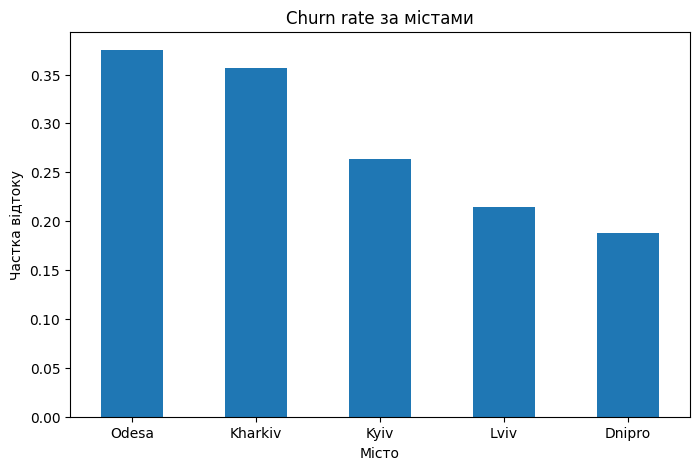

city
Odesa      0.375
Kharkiv    0.357
Kyiv       0.263
Lviv       0.214
Dnipro     0.188
Name: churn, dtype: float64


In [13]:
# 3. Churn rate за містами
churn_by_city = df_clean.groupby("city")["churn"].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
churn_by_city.plot(kind="bar")
plt.title("Churn rate за містами")
plt.xlabel("Місто")
plt.ylabel("Частка відтоку")
plt.xticks(rotation=0)
plt.show()

print(churn_by_city.round(3))

**Інтерпретація.** Частка відтоку відрізняється між містами. Це вказує, що географічна ознака `city` може бути пов’язана з churn, однак для висновку про причинність такого графіка недостатньо.

# Завдання 9. Викиди

In [14]:
Q1 = df_clean["spend"].quantile(0.25)
Q3 = df_clean["spend"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_mask = (
    ~df_clean["spend"].between(lower_bound, upper_bound)
    & df_clean["spend"].notna()
)

outliers = df_clean.loc[outliers_mask, ["customer_id", "city", "segment", "spend"]]
df_no_outliers = df_clean.loc[~outliers_mask]

mean_before = df_clean["spend"].mean()
median_before = df_clean["spend"].median()
mean_after = df_no_outliers["spend"].mean()
median_after = df_no_outliers["spend"].median()

print(f"Нижня межа: {lower_bound:.2f}")
print(f"Верхня межа: {upper_bound:.2f}")
print(f"Знайдено потенційних викидів: {outliers_mask.sum()}")
print("\nПотенційні викиди:")
print(outliers)

print(f"\nДо тимчасового виключення: mean={mean_before:.2f}, median={median_before:.2f}")
print(f"Після тимчасового виключення: mean={mean_after:.2f}, median={median_after:.2f}")

Нижня межа: -480.70
Верхня межа: 1729.40
Знайдено потенційних викидів: 3

Потенційні викиди:
    customer_id   city   segment    spend
6          1007  Odesa     basic  1771.49
34         1035   Lviv  standard  2046.77
67         1068   Kyiv     basic  1972.21

До тимчасового виключення: mean=680.21, median=623.25
Після тимчасового виключення: mean=646.73, median=612.16


**Висновок до завдання 9.** Потенційні викиди впливають на середнє сильніше, ніж на медіану. Автоматично видаляти їх із фінального DataFrame не слід: велика сума витрат може бути не помилкою, а реальною поведінкою цінного клієнта. Перед видаленням потрібно з’ясувати природу таких значень.

# Завдання 10. Підсумковий EDA

In [15]:
# Допоміжні підсумкові показники
overall_churn = df_clean["churn"].mean()
city_churn = df_clean.groupby("city")["churn"].mean().sort_values(ascending=False)

print("Розмір очищеного набору:", df_clean.shape)
print("Середній spend:", round(df_clean["spend"].mean(), 2))
print("Медіанний spend:", round(df_clean["spend"].median(), 2))
print("Загальний churn rate:", round(overall_churn, 3))
print("\nChurn rate за містами:")
print(city_churn.round(3))
print("\nКількість потенційних викидів spend:", len(outliers))

Розмір очищеного набору: (120, 8)
Середній spend: 680.21
Медіанний spend: 623.25
Загальний churn rate: 0.275

Churn rate за містами:
city
Odesa      0.375
Kharkiv    0.357
Kyiv       0.263
Lviv       0.214
Dnipro     0.188
Name: churn, dtype: float64

Кількість потенційних викидів spend: 3


## Підсумковий аналітичний висновок

Початковий набір містив **122 рядки та 8 стовпців**. Після видалення двох повних дублікатів залишилося 120 спостережень. Серед ознак є числові (`age`, `orders`, `spend`), категоріальні (`city`, `segment`), дата реєстрації `signup_date` та цільова змінна `churn`.

Основними проблемами якості були пропущені значення, дублікати, неконсистентне написання назв міст та некоректне від’ємне значення `spend`. Назви міст було нормалізовано, дублікати видалено, а від’ємні витрати позначено як `NaN`.

Статистичний аналіз показує, що середнє `spend` є вищим за медіану, що узгоджується з наявністю великих значень витрат. IQR-аналіз виявляє потенційні викиди, але вони не видаляються автоматично, оскільки можуть бути реальними спостереженнями. Групова аналітика також показує відмінності у churn rate між сегментами та містами.

Візуально гістограма демонструє широкий розподіл віку клієнтів, а boxplot показує відмінності розподілу витрат між сегментами. Стовпчикова діаграма churn rate підтверджує, що частка відтоку неоднакова для різних міст.

Для майбутньої ML-моделі прогнозування `churn` потенційно корисними є `age`, `city`, `segment`, `orders`, `spend`, `tenure_days`, а після об’єднання — `discount_rate` і `support_level`.

Перед моделюванням потрібно спочатку виконати train/test split, а вже потім оцінювати параметри імпутації, масштабування та інших перетворень **лише на train**. Це зменшує ризик data leakage. Категоріальні ознаки можна кодувати, числові пропуски — імпутувати статистиками train, а всі перетворення бажано оформити у preprocessing pipeline.

# Перевірка вимог лабораторної

In [16]:
checks = {
    "Немає повних дублікатів після очищення": df_clean.duplicated().sum() == 0,
    "Назви міст очищено": df_clean["city"].isin(["Kyiv", "Lviv", "Odesa", "Dnipro", "Kharkiv"]).all(),
    "Немає від'ємних spend": not (df_clean["spend"].dropna() < 0).any(),
    "task2 створено": isinstance(task2, pd.DataFrame),
    "merge виконано": isinstance(df_merged, pd.DataFrame),
    "pivot створено": isinstance(pivot_spend, pd.DataFrame),
}
for key, value in checks.items():
    print(f"{key}: {value}")

Немає повних дублікатів після очищення: True
Назви міст очищено: True
Немає від'ємних spend: True
task2 створено: True
merge виконано: True
pivot створено: True
